# ATLAS — NYC taxi pickup EDA

This notebook documents the data checks behind the dashboard. It uses **Pandas and Matplotlib** and runs from the committed 9.31 MB aggregate plus a saved profile of the original Kaggle `train.csv`. The 200.59 MB raw file was removed after preprocessing, so source-wide field types and missing counts below come from that recorded full-file scan; the plots use the retained, aggregated pickups. Run from the repository root or from `notebooks/`.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
processed = root / "data" / "processed"
profile = json.loads((processed / "data_profile.json").read_text(encoding="utf-8"))
aggregate = pd.read_csv(processed / "demand_aggregated.csv", parse_dates=["date"])
assert len(aggregate) == profile["aggregate_rows"]
assert int(aggregate["trip_count"].sum()) == profile["retained_pickups"]
print(f"Raw source: {profile['raw_rows']:,} rows × {profile['raw_columns']} fields")
print(f"Deployed aggregate: {len(aggregate):,} rows × {aggregate.shape[1]} fields")
print(f"Date range: {aggregate['date'].min():%Y-%m-%d} to {aggregate['date'].max():%Y-%m-%d}")
display(aggregate.head())

Raw source: 1,458,644 rows × 11 fields
Deployed aggregate: 239,648 rows × 6 fields
Date range: 2016-01-01 to 2016-06-30


,date,hour,day_type,grid_lat,grid_lon,trip_count
0,2016-01-01,0,Weekday,40.645,-73.775,3
1,2016-01-01,0,Weekday,40.665,-73.975,1
2,2016-01-01,0,Weekday,40.675,-73.975,1
3,2016-01-01,0,Weekday,40.685,-73.995,2
4,2016-01-01,0,Weekday,40.685,-73.985,1


## 1. Shape, field types, and missing values

One raw row is one recorded Yellow Cab trip, with pickups from **2016-01-01 00:00:17** to **2016-06-30 23:59:39**. These are real historical records in a Kaggle competition sample, not all requested or attempted rides.

In [2]:
source_fields = pd.DataFrame({
    "source_dtype": profile["columns"],
    "missing_rows": profile["missing_values"],
})
print("Full-source scan, saved before deleting the raw CSV:")
display(source_fields)
print("Committed aggregate types and missing values:")
display(pd.DataFrame({"aggregate_dtype": aggregate.dtypes.astype(str),
                      "missing_rows": aggregate.isna().sum()}))
print("Invalid pickup datetimes:", profile["invalid_pickup_datetime"])
print("Invalid world coordinates:", profile["invalid_pickup_coordinates"])

Full-source scan, saved before deleting the raw CSV:


,source_dtype,missing_rows
id,str,0
vendor_id,int64,0
pickup_datetime,str,0
dropoff_datetime,str,0
passenger_count,int64,0
pickup_longitude,float64,0
pickup_latitude,float64,0
dropoff_longitude,float64,0
dropoff_latitude,float64,0
store_and_fwd_flag,str,0


Committed aggregate types and missing values:


,aggregate_dtype,missing_rows
date,datetime64[us],0
hour,int64,0
day_type,str,0
grid_lat,float64,0
grid_lon,float64,0
trip_count,int64,0


Invalid pickup datetimes: 0
Invalid world coordinates: 0


The full-source profile records **zero missing values in all 11 fields**. The deployed aggregate also has no missing cells. `pickup_datetime` was stored as text in the raw CSV and validated during preprocessing; the aggregate `date` is parsed as a date when loaded here.

## 2. Distributions and weekday relationship

Daily totals are computed from observed dates, so the weekday comparison divides by the number of observed dates for each weekday rather than comparing unequal raw totals.

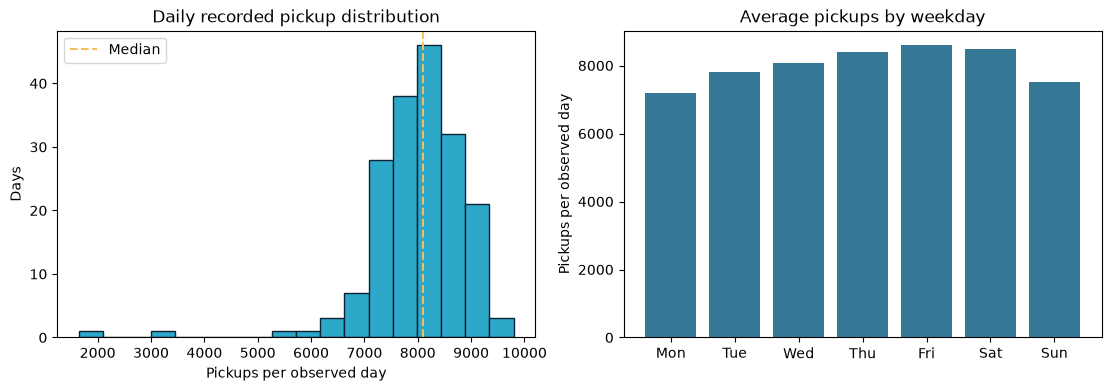

Observed days: 182; daily median: 8,089.5; range: 1,648–9,795
Weekday daily averages: {0: 7206.7, 1: 7796.6, 2: 8080.8, 3: 8405.5, 4: 8596.0, 5: 8493.9, 6: 7512.7}


In [3]:
daily = aggregate.groupby("date", observed=True)["trip_count"].sum().sort_index()
weekday_avg = daily.groupby(daily.index.dayofweek).mean().reindex(range(7))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
axes[0].hist(daily, bins=18, color="#2da8c8", edgecolor="#0b2235")
axes[0].axvline(daily.median(), color="#f6bd60", linestyle="--", label="Median")
axes[0].set(title="Daily recorded pickup distribution", xlabel="Pickups per observed day", ylabel="Days")
axes[0].legend()
axes[1].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"],
            weekday_avg, color="#367795")
axes[1].set(title="Average pickups by weekday", ylabel="Pickups per observed day")
plt.show()
print(f"Observed days: {len(daily)}; daily median: {daily.median():,.1f}; "
      f"range: {daily.min():,}–{daily.max():,}")
print("Weekday daily averages:", weekday_avg.round(1).to_dict())

Across **182 observed days**, daily pickups range from **1,648 to 9,795**; the median is **8,089.5**. Friday averages **8,596** recorded pickups per observed day, compared with Monday's **7,207**. The unusually low day deserves investigation rather than being interpreted as a normal operating level; the dashboard's daily trend lets the manager see it in context.

## 3. Time and location relationships

These plots show where and when recorded pickups concentrate. Grid colors and sizes summarize counts, not available vehicles or unmet ride requests.

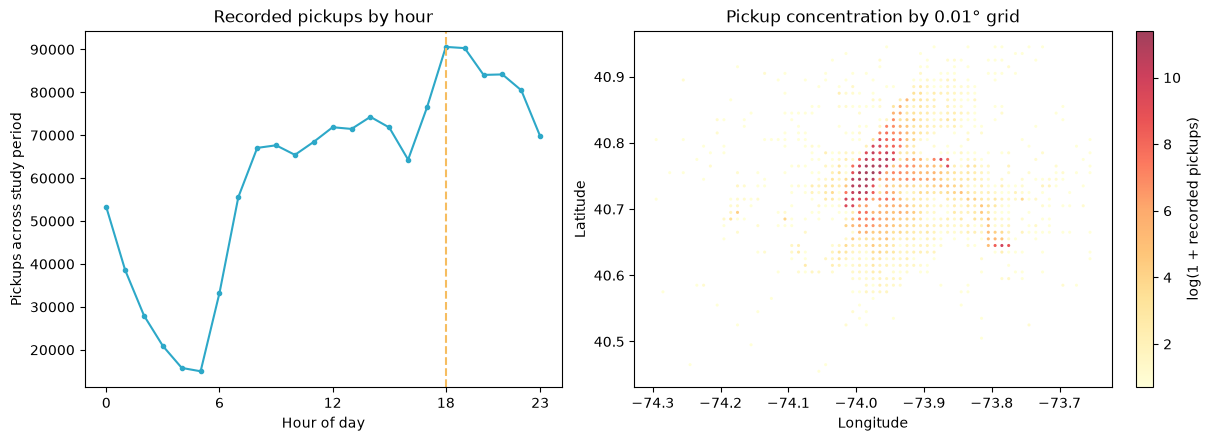

Peak observed hour: 18:00–19:00 with 90,585 pickups
Distinct pickup grids: 885


In [4]:
hourly = aggregate.groupby("hour", observed=True)["trip_count"].sum().reindex(range(24), fill_value=0)
zones = aggregate.groupby(["grid_lat", "grid_lon"], observed=True)["trip_count"].sum().reset_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), constrained_layout=True)
axes[0].plot(hourly.index, hourly.values, marker="o", markersize=3, color="#2da8c8")
axes[0].axvline(int(hourly.idxmax()), color="#f6bd60", linestyle="--")
axes[0].set(title="Recorded pickups by hour", xlabel="Hour of day", ylabel="Pickups across study period",
            xticks=[0, 6, 12, 18, 23])
scatter = axes[1].scatter(zones["grid_lon"], zones["grid_lat"],
                          c=np.log1p(zones["trip_count"]), s=5,
                          cmap="YlOrRd", alpha=.75, linewidths=0)
axes[1].set(title="Pickup concentration by 0.01° grid", xlabel="Longitude", ylabel="Latitude")
fig.colorbar(scatter, ax=axes[1], label="log(1 + recorded pickups)")
plt.show()
print(f"Peak observed hour: {int(hourly.idxmax()):02d}:00–{int(hourly.idxmax()) + 1:02d}:00 "
      f"with {int(hourly.max()):,} pickups")
print(f"Distinct pickup grids: {len(zones):,}")

The busiest observed hour is **18:00–19:00**, with **90,585** pickups across the study period. The spatial plot shows concentrated pickup areas rather than uniform coverage. Those observations justify the Command Center's selected-hour metric, map, and 24-hour supporting chart; the separate analysis page shows longer daily and weekday patterns.

## 4. Cleaning, aggregation, and limits

In [5]:
print(f"Original trips: {profile['raw_rows']:,}")
print(f"Outside broad NYC pickup bounds: {profile['outside_nyc_bounds']:,}")
print(f"Retained pickups: {profile['retained_pickups']:,}")
print(f"Aggregate rows: {len(aggregate):,}; file bytes: {profile['aggregate_bytes']:,}")
print(f"Trips over 24 hours: {profile['trip_duration_over_24_hours']}; "
      f"nonpositive duration: {profile['zero_or_negative_trip_duration']}")
assert profile["raw_rows"] - profile["excluded_pickups"] == profile["retained_pickups"]

Original trips: 1,458,644
Outside broad NYC pickup bounds: 247
Retained pickups: 1,458,397
Aggregate rows: 239,648; file bytes: 9,310,779
Trips over 24 hours: 4; nonpositive duration: 0


The broad NYC pickup box removes **247** records and retains **1,458,397**; grouping by date, hour, day type, and 0.01° pickup cell produces **239,648** aggregate rows. The four trips lasting over 24 hours remain because duration is not used in a pickup-count dashboard. The map's grid centers are approximate, and the source omits unserved requests and driver availability. We therefore excluded passenger-count and trip-duration distributions from the decision page: neither directly changes a regional vehicle-placement decision here. The static 2016 sample supports historical planning, not live dispatch or claims about total market demand.